In [ ]:
!pip install langchain==0.3.24 -q
!pip install langchain-openai -q
!pip install langchain-community -q
!pip install langgraph -q
!pip install -U mypy_extensions -q
!pip install langchain-classic -q

!pip install langchain-tavily -q
!pip install pyowm -qU

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 14.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 461.3/461.3 kB 13.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.0/363.0 kB 5.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.5/66.5 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 31.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
langgraph-prebuilt 1.1.0 requires langchain-core>=1.3.1, but you have langchain-core 0.3.86 which is incompatible.
langgraph 1.2.12 requires langchain-core<2,>=1.4.7, but you have langchain-core 0.3.86 which is incompatible.
langgraph-sdk 0.4.5 requires langchain-core<2,>=1.4.0, but you have langchain-core 0.3.86 which is incompatible.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 145.6/145.6 kB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━

In [ ]:
from typing import Annotated, Sequence, TypedDict
from langchain_core.messages import BaseMessage, ToolMessage, SystemMessage, HumanMessage
from langchain_openai import ChatOpenAI
from langchain_core.tools import tool
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, START, END
from langgraph.prebuilt import ToolNode
from langgraph.checkpoint.memory import MemorySaver

In [ ]:
class AgentState(TypedDict):
    messages: Annotated[Sequence[BaseMessage], add_messages]

In [ ]:
import os
from google.colab import userdata

os.environ['OPENAI_API_KEY'] = userdata.get('API_KEY')

In [ ]:
llm = ChatOpenAI(model = "gpt-4o")

In [ ]:
from langchain_tavily import TavilySearch
from langchain_community.utilities import OpenWeatherMapAPIWrapper
from langchain_classic.agents import load_tools

os.environ["OPENWEATHERMAP_API_KEY"] = userdata.get('OPENWEATHERMAP_API_KEY')
os.environ['TAVILY_API_KEY'] = userdata.get('TAVILY_API_KEY')

# Initialize google search tool
search_tool = TavilySearch()

# Initialize OpenWeatherMap tool
weather = OpenWeatherMapAPIWrapper()

weather_tool = load_tools(["openweathermap-api"], llm)[0]

/tmp/ipykernel_1468/3877581714.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import OpenWeatherMapAPIWrapper


In [ ]:
tools = [search_tool, weather_tool]

In [ ]:
llm_with_tools = llm.bind_tools(tools)

In [ ]:
def llm_call(state:AgentState) -> AgentState:
    system_prompt = SystemMessage(content=
        "You are an intelligent AI assistant."
    )
    response = llm_with_tools.invoke([system_prompt] + state["messages"])
    return {"messages": [response]}


def decision(state: AgentState):
    messages = state["messages"]
    last_message = messages[-1]
    if not last_message.tool_calls:
        return "end"
    else:
        return "continue"

In [ ]:
memory = MemorySaver()

In [ ]:
graph = StateGraph(AgentState)

graph.add_node("agent", llm_call)
tool_node = ToolNode(tools=tools)
graph.add_node("tools", tool_node)

graph.set_entry_point("agent")
graph.add_conditional_edges(
    "agent",
    decision,
    {
        "continue": "tools",
        "end": END,
    },
)
graph.add_edge("tools", "agent")

app = graph.compile(checkpointer=memory, interrupt_before=["tools"])

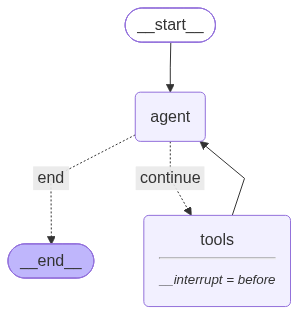

In [ ]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))

In [ ]:
config = {"configurable": {
    "thread_id": 1
}}

In [ ]:
events = app.stream({
    "messages": [HumanMessage(content="What is the current weather in Kandy?")]
}, config=config, stream_mode="values")

for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

What is the current weather in Kandy?
================================== Ai Message ==================================
Tool Calls:
  open_weather_map (call_p3k3cV9f6eiya9ODp9MU5KP4)
 Call ID: call_p3k3cV9f6eiya9ODp9MU5KP4
  Args:
    location: Kandy,LK


In [ ]:
snapshot = app.get_state(config=config)
snapshot.next

('tools',)

In [ ]:
events = app.stream(None, config, stream_mode="values")
for event in events:
    event["messages"][-1].pretty_print()

================================== Ai Message ==================================
Tool Calls:
  open_weather_map (call_p3k3cV9f6eiya9ODp9MU5KP4)
 Call ID: call_p3k3cV9f6eiya9ODp9MU5KP4
  Args:
    location: Kandy,LK
================================= Tool Message =================================
Name: open_weather_map

In Kandy,LK, the current weather is as follows:
Detailed status: moderate rain
Wind speed: 0.97 m/s, direction: 1°
Humidity: 83%
Temperature: 
  - Current: 26.17°C
  - High: 26.17°C
  - Low: 26.17°C
  - Feels like: 26.17°C
Rain: {'1h': 1.61}
Heat index: None
Cloud cover: 100%
================================== Ai Message ==================================

The current weather in Kandy, Sri Lanka is experiencing moderate rain with a cloud cover of 100%. The temperature is 26.17°C, and it feels the same. The wind speed is 0.97 m/s coming from the north. The humidity level is at 83%, and there has been 1.61 mm of rain in the last hour.


In [ ]:
snapshot = app.get_state(config=config)
snapshot.next

()